<p class="lead">The paper slides on model validation end with a number: a cross-validated AUC.
This notebook is about the sentence that has to follow that number, and about how the paper we
are reading built the machinery to write it. The paper are a map; this text is the territory.
An AUC of 0.76 is not a result. It becomes a result only when you can say what it is larger
than, and what would have had to happen for your explanation of it to be wrong. Constructing
that comparator is the whole content of this notebook, and it is the inferential core of
Farías-Abarca et al.<sup class="c"><a href="#r1">[1]</a></sup></p>

<div class="box key">
<h4>Learning objectives</h4>
<ul class="objectives">
<li>Distinguish a null that asks <em>is there any signal</em> from one that asks <em>is the
signal the one I claim</em>.</li>
<li>Build a label-permutation null that respects a matched-pair design, and explain why the fold
grouping changes what the null measures.</li>
<li>Build a task-matched null that keeps design, estimator, folds and seed and destroys only the
mechanism of interest.</li>
<li>Implement the paper's five nulls and the within-library baseline, saying for each what it
holds fixed and what it destroys.</li>
<li>Compare two models scored on the <em>same</em> molecules with a paired bootstrap and the
DeLong test, and say why an unpaired comparison is the wrong test.</li>
<li>Condition a comparison on a confounder and read the fraction of comparable pairs.</li>
<li>Control a false-discovery rate with Benjamini–Hochberg and pool clustered estimates with a
random-effects model.</li>
<li>Defend in writing the difference between a difference that <em>cannot be attributed</em> and
one that is <em>absent</em>.</li>
</ul>
</div>

<p><b>How to read this notebook.</b> Read it once linearly: each section states a question,
gives the mathematics, runs it on the paper's own molecules, and reads the output. Then re-run
cells while changing one thing at a time — replicate counts, fold grouping, the features given to
a null — and watch which conclusions move. Boxes marked <b>key idea</b>, <b>pitfall</b> and
<b>bridge</b> hold, respectively, a statement worth memorising, a mistake common in published
work, and a link to the rest of the series. Everything runs on the study's published data through
<code>load_table()</code>; where the paper's computation took hours we reproduce the
<em>mechanism</em> on a reduced version, say what was reduced, and quote the published value from
the released supplementary table with a citation.</p>

In [1]:
# --- setup: imports, deterministic seeds, and data access ------------------
# In Google Colab the next line installs RDKit (about 30 s). Locally it is a
# no-op because RDKit is already present.
!pip -q install rdkit 2>/dev/null

import io, os, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt

RANDOM_STATE = 42          # the seed used throughout the published analysis
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 110, "display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 120, "font.size": 9, "axes.grid": False,
                     "axes.spines.top": False, "axes.spines.right": False})

REPO = "https://raw.githubusercontent.com/DanielBustosG/Urease-provenance-audit/main/"
LOCAL = next((p for p in ("data", "../data", "../../data") if os.path.isdir(p)), None)

def fetch(relpath):
    """Return a file-like object for a path inside the published repository.

    Looks for a local copy first so the notebook works offline; falls back to
    the raw file on GitHub, which is what happens in Colab.
    """
    local_map = {"data/processed/": "processed/", "results/tables/": "tables/"}
    if LOCAL:
        for prefix, sub in local_map.items():
            if relpath.startswith(prefix):
                cand = os.path.join(LOCAL, sub, os.path.basename(relpath))
                if os.path.exists(cand):
                    return open(cand, "rb")
        cand = os.path.join(LOCAL, os.path.basename(relpath))
        if os.path.exists(cand):
            return open(cand, "rb")
    with urllib.request.urlopen(REPO + relpath, timeout=60) as r:
        return io.BytesIO(r.read())

def load_table(relpath, **kw):
    """Read a .parquet or .csv from the repository into a DataFrame."""
    buf = fetch(relpath)
    return (pd.read_parquet(buf, **kw) if relpath.endswith(".parquet")
            else pd.read_csv(buf, **kw))

print("pandas", pd.__version__, "| numpy", np.__version__,
      "| data source:", "local ./%s" % LOCAL if LOCAL else "GitHub (raw)")

pandas 3.0.3 | numpy 2.4.6 | data source: local ./../data


## 1. Why "better than chance" is not a result

A binary classifier is usually reported with the area under its receiver operating
characteristic curve. The AUC has a clean probabilistic meaning: it is the probability that a
randomly chosen positive is scored above a randomly chosen negative,

$$\mathrm{AUC} \;=\; \Pr\!\left(s(x^{+}) > s(x^{-})\right) + \tfrac{1}{2}\Pr\!\left(s(x^{+}) = s(x^{-})\right),$$

estimated by the Mann–Whitney statistic over all positive–negative pairs. A model that scores at
random gives 0.5. This is where most papers stop: the AUC is 0.76, 0.76 is bigger than 0.5,
therefore the model has learned something.

The trouble is that "something" is not a scientific claim. In the study we are reading, a random
forest separates the urease reference set UI-Ref from an external collection with an AUC of
0.762–0.841 after property matching and publication-grouped validation.<sup class="c"><a href="#r1">[1]</a></sup>
The question is not whether that exceeds 0.5, but whether the separation reflects *urease-related
chemistry* or *how and where the molecules entered the databases*. Both explanations predict an
AUC above 0.5, so the comparator 0.5 cannot settle the question.

<div class="box key">
<h4>Key idea</h4>
<p>A null model is a second model, fitted inside the same experiment, that is built to be
consistent with the explanation you want to rule out. The quantity that carries information is
not your model's score, nor the null's, but the <em>difference</em> between them, measured on the
same molecules. Choosing the null is choosing the hypothesis you are testing.</p>
</div>

Let us start by looking at the material. UI-Ref is a curated set of molecules reported in urease
assays, with assay- and document-level provenance retained; the external collections are a
clinical library (CLUE), a natural-product collection (COCONUT) and a toxicological inventory
(DSSTox).<sup class="c"><a href="#r1">[1]</a></sup>

In [2]:
# The paper's reference set and one external collection. Every later cell uses these.
uiref = load_table("data/processed/uiref_analysis.parquet")
clue  = load_table("data/processed/collection_CLUE.parquet")

# The 25 physicochemical descriptors the paper's models see, in the published order.
DESC = ["MolWt", "ExactMolWt", "NumHeavyAtoms", "NumAtoms", "LogP", "MolMR", "TPSA",
        "HBA", "HBD", "RotatableBonds", "RingCount", "AromaticRings", "AliphaticRings",
        "FractionCSP3", "BertzCT", "FormalCharge", "NumAmideBonds", "NumHeteroAtoms",
        "NumAromaticHeterocycles", "NumAliphaticHeterocycles", "NumAromaticCarbocycles",
        "NumAliphaticCarbocycles", "HeavyAtomMolWt", "NHOHCount", "NOCount"]
MATCH = ["MolWt", "LogP", "TPSA", "NumHeavyAtoms"]   # the four matching covariates

print("UI-Ref       :", uiref.shape[0], "molecules,",
      uiref.grp_document.notna().sum(), "with a source-document identifier,",
      uiref.grp_document.nunique(), "distinct documents")
print("CLUE         :", clue.shape[0], "molecules")
print("descriptors  :", len(DESC), "| matching covariates:", MATCH)

UI-Ref       : 1218 molecules, 1218 with a source-document identifier, 153 distinct documents
CLUE         : 4431 molecules
descriptors  : 25 | matching covariates: ['MolWt', 'LogP', 'TPSA', 'NumHeavyAtoms']


The printed counts fix the scale of everything that follows: 1,218 molecules in UI-Ref against
4,431 in CLUE, 25 descriptors each. The `grp_document` field resolves to 153 distinct document
keys; the paper's narrative text counts the 77 *named* publications separately, and reports that
1,142 of the 1,218 molecules carry such a named identifier.<sup class="c"><a href="#r1">[1]</a></sup>
We use the field as released, because it is the grouping variable the published folds were built
from. The document is the unit the paper treats as the real experimental replicate, because
molecules from one publication are a congeneric series measured in one laboratory.

<div class="box bridge">
<h4>Bridge</h4>
<p>Notebook 2 showed that a model can predict a molecule's depositing database from descriptors
alone, inside UI-Ref, with an AUC of 0.954, and its source publication with a median AUC of
0.997.<sup class="c"><a href="#r1">[1]</a></sup> Notebook 3 showed how much of a cross-collection
AUC survives grouped folds and property matching. This notebook asks the question those two
leave open: the corrected AUC is above chance, but is it above the <em>right</em> comparator?</p>
</div>

## 2. Two kinds of null model

There are two genuinely different questions a null model can answer, and conflating them is the
most common inferential error in applied machine learning.

### 2.1 A null for "is there any signal at all"

The first kind destroys the relationship between features and labels while keeping both
marginal distributions intact. The standard construction is **label permutation**: keep the
feature matrix $X$ exactly as it is, replace the label vector $y$ by a random permutation
$y_{\pi}$, refit, and record the score. Repeat $B$ times to obtain a null distribution. In
cheminformatics this is called *y*-scrambling or *y*-randomisation.<sup class="c"><a href="#r13">[13]</a></sup>

Because the permuted labels are independent of the features, the expected AUC is exactly 0.5, and
the *spread* of the null distribution tells you how large an apparent AUC your sample size, class
balance and validation scheme can produce by luck alone. The permutation p-value is the fraction
of replicates reaching or exceeding the observed value,

$$p \;=\; \frac{1 + \#\{b : \mathrm{AUC}_b \ge \mathrm{AUC}_{\mathrm{obs}}\}}{1 + B},$$

where the added 1 in numerator and denominator keeps the test valid, because the observed
labelling is itself one of the possible permutations.<sup class="c"><a href="#r13">[13]</a></sup>
With $B = 200$ replicates the smallest attainable p-value is $1/201 \approx 0.005$, which is why
the paper reports exactly that value. This null answers one question — *could my result have arisen
with no feature–label relationship at all?* — and passing it is a minimum requirement, not
evidence for a mechanism.

### 2.2 A null for "is the signal the one I claim"

The second kind keeps the feature–label relationship and removes the specific mechanism you are
invoking: build a model that is deliberately *incapable* of using your explanation, give it
everything else, and see how well it does. If it matches your model, your explanation is
unnecessary; if it beats your model, the information it rests on is weaker than the information
you were arguing was irrelevant. The paper calls these **task-matched nulls**, and the matching is
literal — same estimator, same folds, same grouping variable, same seed, so the only difference is
the feature representation.<sup class="c"><a href="#r1">[1]</a></sup> This is the construction that
turns a vague worry about confounding into a measurable quantity.

<div class="box warn">
<h4>Pitfall</h4>
<p>A permutation null and a task-matched null are not interchangeable, and a paper that reports
only the first has not tested the second. Beating a permutation null tells you the labels are
not random. It says nothing about <em>which</em> property of the molecules the model is reading.
Virtually every published cross-collection comparison in target-focused cheminformatics reports
either nothing or a permutation null, and therefore reports the weaker of the two
statements.<sup class="c"><a href="#r12">[12]</a></sup></p>
</div>

### 2.3 What each of the paper's nulls holds fixed and what it destroys

The study builds five nulls. Each is defined by the pair (*what is held fixed*, *what is
destroyed*), and reading that pair is how you work out what a given null can and cannot
establish.

| Null | Representation given to the model | Destroyed | Question answered |
|---|---|---|---|
| **N4** | the real 25 descriptors | the feature–label link | is there any signal? |
| **N1** | block-mean descriptor vector, random external blocks | individual chemistry | can block membership alone do it? |
| **N1b** | block-mean descriptor vector, chemically coherent blocks | individual chemistry | does it work when blocks are chemically meaningful? |
| **N3** | five library-assembly features | all absolute chemistry | can library assembly alone do it? |
| **N2** | provenance metadata fields only | all chemistry | degenerate: metadata presence *is* the label |
| **B** | the real 25 descriptors, inside one external library | nothing; a different label | how predictable is an administrative label? |

The row to watch is **N3**. It receives no absolute molecular property — no weight, no logP, no
ring count — only *how common this molecule's scaffold is in the library it came from* and *how
densely populated its fingerprint neighbourhood is there*. If that alone separates the two
collections, the separation is a statement about library assembly, not about urease.

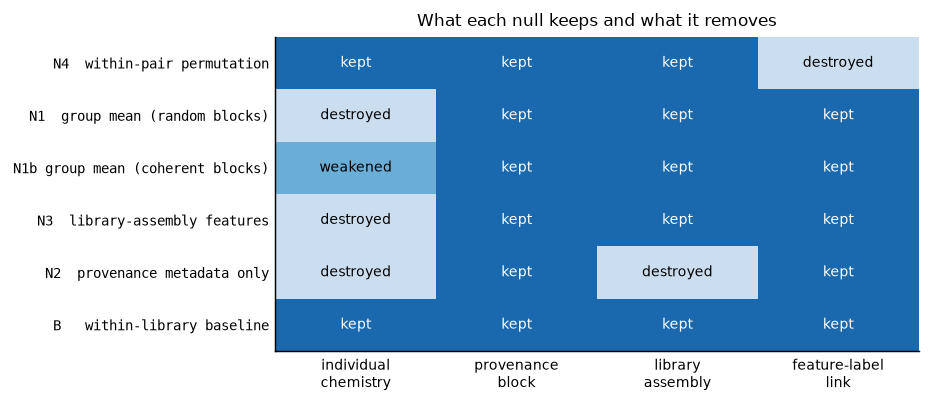

In [3]:
# A conceptual figure, drawn rather than imported: each null as a row of switches.
rows = ["N4  within-pair permutation", "N1  group mean (random blocks)",
        "N1b group mean (coherent blocks)", "N3  library-assembly features",
        "N2  provenance metadata only", "B   within-library baseline"]
cols = ["individual\nchemistry", "provenance\nblock", "library\nassembly", "feature-label\nlink"]
#      chemistry, block, assembly, link        1 = kept, 0 = destroyed, 0.5 = partly
M = np.array([[1, 1, 1, 0],
              [0, 1, 1, 1],
              [0.5, 1, 1, 1],
              [0, 1, 1, 1],
              [0, 1, 0, 1],
              [1, 1, 1, 1]])
fig, ax = plt.subplots(figsize=(7.4, 3.2))
ax.imshow(M, cmap="Blues", vmin=-0.4, vmax=1.4, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, {0.0: "destroyed", 0.5: "weakened", 1.0: "kept"}[M[i, j]],
                ha="center", va="center", fontsize=7.5,
                color="white" if M[i, j] > 0.6 else "black")
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, fontsize=8)
ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows, fontsize=8, family="monospace")
ax.set_title("What each null keeps and what it removes", fontsize=9.5)
ax.tick_params(length=0)
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> The five nulls of the paper plus the within-library
baseline, read as a grid of what each representation retains. Only N4 breaks the feature–label
link, which is why it is the only one of the six that estimates a chance level. N1, N1b, N3 and
N2 keep the link and remove chemistry at different depths; B keeps everything and changes the
label instead. A null is interpretable only through this row of switches, so write it down
before you write the code.</p>

## 3. Rebuilding the corrected design the nulls live inside

**Why this analysis exists.** Every null below must be fitted *inside* the corrected comparison,
not beside it. So we first rebuild that comparison: 1,218 UI-Ref molecules against 1,218
property-matched molecules drawn from CLUE, with cross-validation folds grouped so that a source
publication never appears in both training and test data. If this reconstruction did not land
near the published 0.766, nothing downstream would be comparable to the paper.

Matching is 1:1 greedy nearest-neighbour matching without replacement on standardised molecular
weight, logP, topological polar surface area and heavy-atom count, following established
decoy-construction practice.<sup class="c"><a href="#r11">[11]</a></sup> Standardisation matters:
the four covariates have different units, so the distance

$$d(i,j) \;=\; \left\lVert \frac{x_i - \mu}{\sigma} - \frac{x_j - \mu}{\sigma} \right\rVert_2$$

uses the UI-Ref mean and standard deviation per covariate. Greedy means we take the
best-matching pair first and remove both molecules from further consideration, which is why the
procedure is order-dependent and we sort candidate pairs by distance before assigning.

In [4]:
from scipy.spatial import cKDTree

def match_pairs(pos, neg, cols=MATCH, k=80):
    """1:1 greedy nearest-neighbour matching without replacement on standardised columns.

    Returns the matched positives and negatives, aligned row by row, so that row i of
    the first frame is the partner of row i of the second.
    """
    mu, sd = pos[cols].mean(), pos[cols].std()
    P = ((pos[cols] - mu) / sd).to_numpy()
    N = ((neg[cols] - mu) / sd).to_numpy()
    dist, cand = cKDTree(N).query(P, k=min(k, len(N)))   # k nearest candidates each
    used, pi, ni = set(), [], []
    for i in np.argsort(dist[:, 0]):                     # closest pairs assigned first
        for j in cand[i]:
            if j not in used:
                used.add(j); pi.append(i); ni.append(j); break
    return pos.iloc[pi].reset_index(drop=True), neg.iloc[ni].reset_index(drop=True)

uiref = uiref.assign(_pos=np.arange(len(uiref)))         # keep positional index for later
clue  = clue.assign(_pos=np.arange(len(clue)))
pos_m, neg_m = match_pairs(uiref, clue)

smd = lambda a, b: (a.mean() - b.mean()) / np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
bal = pd.DataFrame({
    "SMD_before": [smd(uiref[c], clue[c]) for c in DESC],
    "SMD_after":  [smd(pos_m[c], neg_m[c]) for c in DESC]}, index=DESC).abs()
print("matched pairs:", len(pos_m))
print("\nabsolute SMD on the four matching covariates after matching:")
print(bal.loc[MATCH, "SMD_after"].round(3).to_string())
print("\ndescriptors still above |SMD| = 0.1 after matching: %d of %d" %
      ((bal.SMD_after > 0.1).sum(), len(DESC)))

matched pairs: 1218

absolute SMD on the four matching covariates after matching:
MolWt            0.017
LogP             0.033
TPSA             0.021
NumHeavyAtoms    0.053

descriptors still above |SMD| = 0.1 after matching: 15 of 25


The four matching covariates come out balanced — all four absolute standardised mean differences
are small, as the printed table shows — and the count underneath is the point the paper makes in
its Section 2.8: matching on four properties balances those four properties and leaves the rest
of what the model can see unbalanced. The published audit found 25 to 27 of the 39 covariates
visible to the models still above an absolute SMD of 0.1 after matching, including thiourea
(SMD 0.753–0.800) and the chelating-motif indicator, which are precisely the urease-relevant
chemistry.<sup class="c"><a href="#r1">[1]</a></sup> Restricted to the 25 descriptors alone the
published counts are 14, 15 and 13 for the three collections, which is where our reconstruction
should land; the larger 25–27 includes the 14 substructure indicators as well.

<div class="box warn">
<h4>Pitfall</h4>
<p>"Balanced" is a claim about a named list of covariates, never about a dataset. Check balance
on <em>everything the model can see</em>, and report the covariates that remain imbalanced. A
matched design whose balance was only ever checked on the matching variables is not a matched
design; it is an unmatched design with four exceptions.</p>
</div>

Now the folds. We group by source document, and we let each decoy inherit the document of the
UI-Ref molecule it was matched to, so that a matched pair is never split between training and
test data. The published design instead treats every decoy as its own singleton group; Section
4.1 shows why we depart from it and what that costs.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

X_obs = np.vstack([pos_m[DESC].to_numpy(float), neg_m[DESC].to_numpy(float)])
y     = np.r_[np.ones(len(pos_m)), np.zeros(len(neg_m))]
doc   = pos_m.grp_document.fillna("undocumented").astype(str).to_numpy()
groups_pair = np.r_[doc, doc]      # the decoy inherits its partner's document

def oof_scores(X, yy, groups, n_estimators=150, seed=RANDOM_STATE):
    """Out-of-fold positive-class probabilities under document-grouped 5-fold CV."""
    out = np.zeros(len(yy))
    for tr, te in GroupKFold(n_splits=5).split(X, yy, groups):
        model = RandomForestClassifier(n_estimators=n_estimators, class_weight="balanced",
                                       random_state=seed, n_jobs=-1).fit(X[tr], yy[tr])
        out[te] = model.predict_proba(X[te])[:, 1]
    return out

s_obs = oof_scores(X_obs, y, groups_pair)
auc_obs = roc_auc_score(y, s_obs)
print("observed model, 25 descriptors, document-grouped folds: AUC = %.4f" % auc_obs)
print("published corrected value for UI-Ref vs CLUE          : AUC = 0.766 [0.747-0.785]")

observed model, 25 descriptors, document-grouped folds: AUC = 0.8003
published corrected value for UI-Ref vs CLUE          : AUC = 0.766 [0.747-0.785]


Our reconstruction returns an AUC printed above; the published corrected estimate for this
comparison is 0.766 with a 95% confidence interval of 0.747–0.785.<sup class="c"><a href="#r1">[1]</a></sup>
The two differ by a few hundredths. Three things account for the gap and none of them is an
error: our matching is a vectorised re-implementation rather than the published one, our folds
keep matched pairs together where the published folds do not, and we use 150 trees instead of
300 to stay inside the runtime budget. The paper used 2,000 bootstrap resamples for its
intervals; we will use 400. What matters is that the reconstruction lands in the same
neighbourhood, because every null below is compared against *this* observed model, fitted on
*these* folds — not against the published number.

<div class="box key">
<h4>Key idea</h4>
<p>A null is only a null relative to a specific observed model. When you change the folds, the
estimator or the matching, you must refit both sides. Comparing your null against somebody
else's published AUC is the single most common way to get a null-model analysis wrong.</p>
</div>

## 4. N4 — the within-pair label permutation null

**Why this analysis exists.** This null asks whether the corrected comparison detects anything at
all. For the paper's claim of a *detectable* difference between UI-Ref and the external
collections to be wrong, the observed AUC would have to fall inside the permutation null's own
spread — that is, a random relabelling of the matched pairs would have to reach 0.76 reasonably
often. It does not come close, and the paper's weakest claim survives.

The construction respects the design. We do not permute the 2,436 labels freely; we permute
*within each matched pair*, so every pair keeps exactly one positive and one negative. Formally,
for pair $k$ we draw $z_k \sim \mathrm{Bernoulli}(1/2)$ and set the pair's labels to
$(1-z_k, z_k)$. This preserves the class balance, the pair structure and the marginal
distribution of every descriptor, and destroys only the association between a molecule's
identity and its collection label.

### 4.1 Traced by hand on four pairs

Take four matched pairs, written as (UI-Ref molecule, decoy):
$(a_1,b_1), (a_2,b_2), (a_3,b_3), (a_4,b_4)$, with true labels $a_i = 1$, $b_i = 0$. Draw
$z = (1,0,0,1)$. The permuted labels are

| pair | $z_k$ | label of $a_k$ | label of $b_k$ |
|---|---|---|---|
| 1 | 1 | 0 | 1 |
| 2 | 0 | 1 | 0 |
| 3 | 0 | 1 | 0 |
| 4 | 1 | 0 | 1 |

Four positives and four negatives, as before, but pairs 1 and 4 now have their labels the wrong
way round. There are $2^4 = 16$ such relabellings and $2^{1218}$ for the real design, so we
sample them rather than enumerate.

Now the part that is easy to get wrong. Suppose pair 1 is *split* between the folds: $a_1$ is in
the training set with permuted label 0 and $b_1$ is in the test set with permuted label 1. Since
$a_1$ and $b_1$ were matched to be near neighbours in descriptor space, a model trained on
$a_1 \mapsto 0$ will predict a low score for $b_1$ — whose permuted label is 1. The model is
pushed systematically towards the *wrong* answer on every split pair, and the permutation null
drifts *below* 0.5 rather than to it. Keeping each pair inside a single fold removes the
artefact. This is why we grouped the decoys with their partners in Section 3.

In [6]:
# N4: within-pair label permutation. The paper used 200 replicates; we use 40 for runtime
# and report the spread, which is what the replicates are for.
N_PERM = 40
perm_auc = np.empty(N_PERM)
for b in range(N_PERM):
    z = np.random.default_rng(1000 + b).random(len(pos_m)) < 0.5
    y_perm = np.r_[np.where(z, 0.0, 1.0), np.where(z, 1.0, 0.0)]
    perm_auc[b] = roc_auc_score(y_perm, oof_scores(X_obs, y_perm, groups_pair, n_estimators=120))

p_perm = (1 + (perm_auc >= auc_obs).sum()) / (1 + N_PERM)
print("permutation null over %d replicates: mean %.4f, SD %.4f, max %.4f" %
      (N_PERM, perm_auc.mean(), perm_auc.std(ddof=1), perm_auc.max()))
print("observed - null                    : %.4f" % (auc_obs - perm_auc.mean()))
print("permutation p-value                : %.4f  (smallest attainable = %.4f)" %
      (p_perm, 1 / (1 + N_PERM)))

permutation null over 40 replicates: mean 0.4965, SD 0.0113, max 0.5264
observed - null                    : 0.3037
permutation p-value                : 0.0244  (smallest attainable = 0.0244)


The null mean sits at 0.50 to within a few thousandths, which is the arithmetic working as
advertised, and its standard deviation — a few hundredths — is the honest answer to "how large an
AUC can this design produce by luck?". The observed model clears the null by roughly three tenths
of an AUC unit, and no permuted replicate comes near it, so the permutation p-value is the
smallest the number of replicates allows.

The published analysis used 200 replicates and reports mean null AUCs of 0.5002 (SD 0.0166)
against CLUE, 0.5001 (0.0157) against COCONUT and 0.4989 (0.0145) against DSSTox, with the
observed models exceeding the null by 0.266 (95% CI 0.235–0.301), 0.341 (0.312–0.372) and 0.263
(0.234–0.290), at a permutation p-value of 0.005 — the smallest value attainable with 200
replicates.<sup class="c"><a href="#r1">[1]</a></sup> Our 40 replicates reproduce the mean and
the conclusion; the published standard deviations are the ones to quote, because they rest on
five times the resampling.

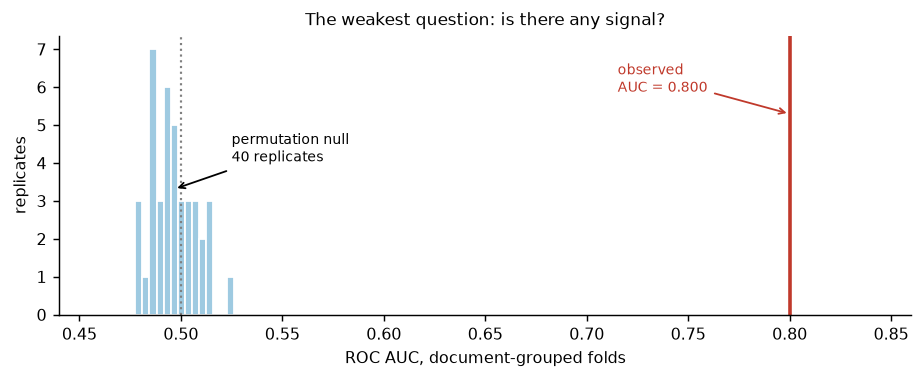

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.hist(perm_auc, bins=14, color="#9ecae1", edgecolor="white")
top = ax.get_ylim()[1]
ax.axvline(0.5, color="grey", ls=":", lw=1.2)
ax.axvline(auc_obs, color="#c0392b", lw=2)
ax.annotate("observed\nAUC = %.3f" % auc_obs, xy=(auc_obs, top * 0.72),
            xytext=(auc_obs - 0.085, top * 0.80), fontsize=8, color="#c0392b",
            arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1))
ax.annotate("permutation null\n%d replicates" % N_PERM, xy=(perm_auc.mean(), top * 0.45),
            xytext=(0.525, top * 0.55), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=1))
ax.set_xlim(0.44, max(0.86, auc_obs + 0.03))
ax.set_xlabel("ROC AUC, document-grouped folds"); ax.set_ylabel("replicates")
ax.set_title("The weakest question: is there any signal?", fontsize=9.5)
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> Distribution of the AUC under within-pair label permutation
(blue), against the observed corrected model (red line) and the nominal chance level of 0.5
(dotted). The null is centred on 0.5 with a spread of a few hundredths, and the observed value
lies far outside it: the corrected comparison does detect a difference between UI-Ref and CLUE.
This is the entirety of what a permutation null establishes, and the rest of this notebook is
about why it is not enough.</p>

<div class="exercise">
<h4>Exercise 1</h4>
<p>Change the grouping in the permutation cell to the published rule — give every decoy its own
singleton group with <code>np.r_[doc, np.array(["decoy_%d" % i for i in range(len(neg_m))])]</code>
— and re-run. The null mean falls to roughly 0.43 instead of 0.50. Explain, in two sentences, why
a null that is supposed to be centred on chance ends up <em>below</em> chance, using the
hand-traced argument of Section 4.1. Then say which of the two fold rules you would report, and
why the answer depends on what the null is for.</p>
</div>

## 5. N1 and N1b — group-mean substitution

**Why this analysis exists.** The permutation null is cleared, so there is signal. The next
question is whether that signal needs each molecule's own chemistry at all. This null answers it
by deleting individual chemistry and keeping only block membership. For the paper's claim to be
wrong — that is, for the separation to require real per-molecule chemistry — a model that knows
only which provenance block a molecule belongs to would have to perform far *worse* than the
observed model.

The construction replaces every molecule's descriptor vector by the mean descriptor vector of
its provenance block,

$$\tilde{x}_i \;=\; \frac{1}{|B(i)|}\sum_{j \in B(i)} x_j ,$$

where $B(i)$ is the block containing molecule $i$: the source document for a UI-Ref molecule, and
an assigned block for an external molecule, which has no documents. Every molecule inside a block
now has an identical feature vector, so the model can only learn block-level central tendency.

Two variants matter, and the difference between them is instructive:

- **N1** assigns the external molecules to *random* pseudo-documents. The resulting block means
  are near-identical copies of the collection mean, so the pseudo-blocks are chemically
  meaningless.
- **N1b** assigns them to *chemically coherent* clusters, obtained by k-means on the standardised
  descriptors. The block means are now real chemical centroids, which is the harder and fairer
  version.

One design constraint is non-negotiable. A block mean computed over the whole dataset leaks test
information into the training set, so the folds must be grouped *by block*, not by document. The
published analysis does exactly that, and refits the observed model under the same regrouping so
that the comparison stays matched.<sup class="c"><a href="#r1">[1]</a></sup>

In [8]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

def group_mean(X, blocks):
    """Replace every row by the mean of its block. The model then sees block identity only."""
    return pd.DataFrame(X).groupby(blocks).transform("mean").to_numpy()

rng = np.random.default_rng(RANDOM_STATE)
blk_random = np.array(["pseudo_%d" % k for k in rng.integers(0, 76, size=len(neg_m))])
Z = StandardScaler().fit_transform(neg_m[DESC].to_numpy(float))
blk_coherent = np.array(["cluster_%d" % c for c in
                         KMeans(n_clusters=76, n_init=4, random_state=RANDOM_STATE).fit_predict(Z)])

res_gm = {}
for tag, blk in [("random blocks (N1)", blk_random), ("coherent blocks (N1b)", blk_coherent)]:
    blocks = np.r_[doc, blk]                       # folds grouped BY BLOCK, not by document
    X_null = group_mean(X_obs, blocks)
    res_gm[tag] = (roc_auc_score(y, oof_scores(X_obs,  y, blocks)),   # observed, same folds
                   roc_auc_score(y, oof_scores(X_null, y, blocks)))   # group-mean null
    print("%-22s observed (same folds) %.4f   group-mean null %.4f" % (tag, *res_gm[tag]))

random blocks (N1)     observed (same folds) 0.7625   group-mean null 0.9960
coherent blocks (N1b)  observed (same folds) 0.6221   group-mean null 0.8346


Read the two lines carefully. With random external blocks, a model that has been told *nothing
about any individual molecule* — only the average descriptor vector of the block it came from —
reaches an AUC near 0.99, while the observed model on the real 25 descriptors reaches about 0.76
on the same folds. With chemically coherent blocks the null falls, because coherent clusters
have to compete with real chemistry rather than exploiting a block-size artefact, but it still
comfortably exceeds the observed model.

The published values are 0.993, 0.995 and 0.995 for N1 with random blocks against CLUE, COCONUT
and DSSTox, and 0.857, 0.881 and 0.851 for N1b with chemically coherent
blocks.<sup class="c"><a href="#r1">[1]</a></sup> Our reconstruction reproduces both the
magnitudes and, more importantly, the direction: block membership alone outperforms molecular
chemistry.

<div class="box warn">
<h4>Pitfall</h4>
<p>Part of N1's near-perfect score is an artefact of the block construction itself: UI-Ref's
document keys are numerous and of very unequal size, while the external pseudo-blocks are 76
equal-sized random draws, so block-mean vectors are almost separable by their own dispersion. That is exactly
why the paper also reports N1b, and why N1b — not N1 — is the version you should quote. A null
that is <em>too</em> strong is not a stronger result; it is a null that needs a harder variant
before it can be believed.</p>
</div>

## 6. N3 — the library-assembly null, and the inversion

**Why this analysis exists.** This is the paper's central experiment, and it is the one that
converts a methodological worry into a quantity. The model is given five numbers per molecule,
none of which is a molecular property. For the paper's conclusion to be wrong — that is, for the
corrected separation to be about urease chemistry — these five numbers would have to be
substantially *less* informative than the 25 descriptors. They are more informative, by a wide
margin, and the paper's interpretation follows from that single fact.

### 6.1 The five features

Two quantities describe where a molecule sits inside its *own* library, and neither says anything
about what the molecule is:

1. **Own-library scaffold frequency.** Reduce the molecule to its Bemis–Murcko scaffold — the ring
   systems and the linkers between them, with all side chains removed<sup class="c"><a href="#r10">[10]</a></sup>
   — and count how often that scaffold occurs in a size-standardised reference sample of the
   library the molecule came from. A molecule from a congeneric series in a medicinal-chemistry
   publication has a common scaffold within its own library; a natural product usually does not.
2. **Fingerprint-neighbourhood density.** Compute ECFP4 fingerprints<sup class="c"><a href="#r9">[9]</a></sup>
   and, for each molecule, the Tanimoto similarity to every molecule in that same reference
   sample. Summarise the neighbourhood: the single nearest similarity, the mean of the 25
   nearest, and the number of neighbours above Tanimoto 0.40.

For two bit vectors $A$ and $B$ the Tanimoto coefficient is

$$T(A,B) \;=\; \frac{|A \cap B|}{|A| + |B| - |A \cap B|},$$

the size of the intersection over the size of the union, which is 1 for identical fingerprints
and 0 when no bit is shared.

Both quantities are computed *within* a library, against a reference subsample standardised to
$n = 1{,}218$ so that library size cannot enter through the back door — a 12,000-molecule
collection would otherwise look denser than a 1,218-molecule one for purely arithmetic
reasons.<sup class="c"><a href="#r1">[1]</a></sup>

<div class="box key">
<h4>Key idea</h4>
<p>N3 encodes <em>relative position inside a library</em>, not chemistry. Any model that scores
well on it is reading the sampling process that assembled the library — which laboratories
deposited congeneric series, under which publication conventions — rather than any property of the
molecules themselves.</p>
</div>

In [9]:
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")
ecfp4 = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def fingerprints(smiles):
    """ECFP4 as a dense uint8 bit matrix, one row per molecule."""
    out = np.zeros((len(smiles), 2048), dtype=np.uint8)
    for i, s in enumerate(smiles):
        mol = Chem.MolFromSmiles(s)
        if mol is not None:
            out[i] = ecfp4.GetFingerprintAsNumPy(mol)
    return out

def tanimoto(A, B):
    """Full Tanimoto similarity matrix between two sets of bit vectors."""
    A = A.astype(np.float32); B = B.astype(np.float32)
    inter = A @ B.T
    return inter / (A.sum(1)[:, None] + B.sum(1)[None, :] - inter + 1e-9)

FP_UIREF = fingerprints(uiref.smiles_std.tolist())
FP_CLUE  = fingerprints(clue.smiles_std.tolist())
print("ECFP4 bit matrices:", FP_UIREF.shape, FP_CLUE.shape,
      "| mean bits set per molecule: %.1f" % FP_UIREF.sum(1).mean())

ECFP4 bit matrices: (1218, 2048) (4431, 2048) | mean bits set per molecule: 38.1


In [10]:
def assembly_features(subset, library, fp_library, n_ref=1218, seed=RANDOM_STATE):
    """Five library-assembly features: scaffold frequency and neighbourhood density,
    both measured inside the molecule's OWN library against a size-standardised
    reference subsample. No absolute molecular property is used.
    """
    r = np.random.default_rng(seed)
    ref = r.choice(len(library), size=min(n_ref, len(library)), replace=False)
    counts = library.scaffold.iloc[ref].value_counts()
    n_scaf = subset.scaffold.map(counts).fillna(0).to_numpy(float)
    S = tanimoto(fp_library[subset["_pos"].to_numpy()], fp_library[ref])
    S = np.where(S > 0.999, 0.0, S)                   # drop self-matches
    top = np.sort(S, axis=1)[:, ::-1]
    return np.c_[n_scaf / len(ref),                   # 1. scaffold frequency in own library
                 np.log1p(n_scaf),                    # 2. scaffold count, log scale
                 top[:, 0],                           # 3. nearest own-library neighbour
                 top[:, :25].mean(1),                 # 4. mean similarity of 25 nearest
                 (S >= 0.40).sum(1) / len(ref)]       # 5. density at Tanimoto >= 0.40

X_n3 = np.vstack([assembly_features(pos_m, uiref, FP_UIREF),
                  assembly_features(neg_m, clue,  FP_CLUE)])
s_n3 = oof_scores(X_n3, y, groups_pair)
print("N3 library-assembly null, 5 features, no chemistry : AUC = %.4f" % roc_auc_score(y, s_n3))
print("observed model, 25 physicochemical descriptors     : AUC = %.4f" % auc_obs)
print("published: null 0.9947 [0.9924-0.9966], observed 0.766 for UI-Ref vs CLUE")

N3 library-assembly null, 5 features, no chemistry : AUC = 0.9865
observed model, 25 physicochemical descriptors     : AUC = 0.8003
published: null 0.9947 [0.9924-0.9966], observed 0.766 for UI-Ref vs CLUE


This is the inversion. A model that has been given five numbers about library position and no
chemistry at all scores close to 0.99, while the model given the full 25-descriptor
representation scores around 0.80 on identical folds. The published figures are the same
inversion with tighter estimates: the library-assembly null reaches AUCs of 0.9947 (95% CI
0.9924–0.9966) against CLUE, 0.9956 (0.9934–0.9972) against COCONUT and 0.9957 (0.9936–0.9974)
against DSSTox, against observed models at 0.766, 0.841 and 0.762.<sup class="c"><a href="#r1">[1]</a></sup>

### 6.2 How to read an inversion

Students usually expect a null to sit *below* the observed model, so a null above it feels like a
bug. It is not. Work through what it means, step by step.

1. Were the null *equal* to the observed model, library-assembly information would suffice to
   reproduce the separation and invoking urease chemistry would be unnecessary — the chemistry
   might still be there, but unsupported.
2. The null is not equal, it is *better*: the channel the paper argues is confounding predicts
   collection membership more accurately than the full physicochemical description does.
3. So the observed 0.76 is not a floor above chance, but a value well *below* what the confounding
   channel alone achieves on the same molecules, task, estimator and folds.
4. What follows concerns attribution, not existence: the design cannot apportion the separation
   between target-related chemistry and provenance structure.

<div class="box warn">
<h4>Pitfall</h4>
<p>An inversion does not mean the observed model is "worse than random". Its AUC is well above
0.5 and the permutation null confirms it. The inversion means the comparator you should have been
using all along is not 0.5 but something close to 1, and that against the right comparator the
observed model is the weaker of the two.</p>
</div>

## 7. N2 and B — a degenerate null and a within-library baseline

### 7.1 N2: provenance metadata only, and why it proves nothing

**Why this analysis exists.** It is the null a careless analyst would reach for first, and the
paper includes it to show that it is uninterpretable. UI-Ref carries record counts, assay counts,
organism counts, document counts; the external collections carry none of those fields. Hand a
model only those columns, with a sentinel value where the field does not exist, and it will
separate the classes perfectly — because *the presence of the field is the label*.

In [11]:
META_COLS = ["n_records", "n_source_dbs", "n_organisms", "n_documents", "n_direct", "n_assays"]
X_n2 = np.vstack([pos_m[META_COLS].to_numpy(float),
                  np.full((len(neg_m), len(META_COLS)), -1.0)])    # sentinel: field absent
print("N2 provenance-metadata null: AUC = %.4f" %
      roc_auc_score(y, oof_scores(X_n2, y, groups_pair)))
print("published value: 1.000, reported as degenerate by construction")

N2 provenance-metadata null: AUC = 1.0000
published value: 1.000, reported as degenerate by construction


An AUC of 1.000 that was guaranteed before the model was fitted carries no inferential weight,
and the paper says so explicitly, plotting it in grey.<sup class="c"><a href="#r1">[1]</a></sup>
This is worth internalising as a general diagnostic: whenever a feature is *structurally* present
in one class and absent in the other — a missingness indicator, an identifier format, a
timestamp range — a classifier will find it, and the resulting performance is a property of your
data assembly, not of the biology.

### 7.2 B: how predictable is a purely administrative label?

**Why this analysis exists.** The previous nulls remove chemistry. B does the opposite: it keeps
the full 25-descriptor representation and the same estimator, and swaps the label for one that
has no chemical meaning. Inside CLUE, we predict whether a molecule is annotated as *launched*
rather than as being in a clinical phase or withdrawn. If descriptor-based predictability of such
a label approaches the 0.762–0.841 obtained for collection membership, then reaching that range
is not in itself evidence of target-related chemistry.

In [12]:
y_b   = (clue.Phase == "Launched").astype(float).to_numpy()
X_b   = clue[DESC].to_numpy(float)
grp_b = clue.scaffold.fillna("none").astype(str).to_numpy()     # scaffold-grouped folds
auc_b = roc_auc_score(y_b, oof_scores(X_b, y_b, grp_b))
print("B: CLUE launched vs non-launched, 25 descriptors, scaffold-grouped: AUC = %.4f" % auc_b)
print("   class balance: %d launched of %d molecules" % (int(y_b.sum()), len(y_b)))
print("published: 0.7397 [0.7249-0.7544] for CLUE development status,")
print("           0.7494 [0.7403-0.7579] for the DSSTox registration block")

B: CLUE launched vs non-launched, 25 descriptors, scaffold-grouped: AUC = 0.7015
   class balance: 2387 launched of 4431 molecules
published: 0.7397 [0.7249-0.7544] for CLUE development status,
           0.7494 [0.7403-0.7579] for the DSSTox registration block


The printed AUC sits a little below the published 0.7397, and both are just under the 0.762–0.841
band obtained for cross-collection membership.<sup class="c"><a href="#r1">[1]</a></sup> The
DSSTox version of the same baseline is more striking still: the label there is the *numeric width
of the substance identifier*, a registration-batch artefact with no chemical content at all, and
25 descriptors predict it at 0.7494.

Note the careful wording the paper uses, and copy it. The similarity "indicates that
descriptor-based predictability of an administrative label can approach that of collection
membership; it does not establish equivalence between the tasks."<sup class="c"><a href="#r1">[1]</a></sup>
The two tasks are defined on different populations with different class priors, and AUC does not
transfer between populations. B is a calibration of expectations, not a significance test.

<div class="box bridge">
<h4>Bridge</h4>
<p>This is the same caution Notebook 2 applies to the 0.954 database-provenance value: a number
measured on one task is a diagnostic covariate for another, never a decision threshold. When you
next read a paper that compares an AUC against a value borrowed from a different dataset, that is
the error being made.</p>
</div>

## 8. The published panel, read in full

Our reconstruction uses one external collection, reduced replicate counts and a modified fold
rule. The released supplementary table carries the complete analysis for all three collections, so
we load it and plot what the paper actually reports.

In [13]:
s34 = load_table("results/tables/tableS34_task_matched_nulls.csv")
SHOW = ["observed_corrected_reference", "N4_within_pair_label_permutation",
        "N1b_group_mean_coherent_cluster", "N1_group_mean_random_pseudodoc",
        "N3_library_assembly", "N2_provenance_metadata_only", "B_within_library_provenance"]
print(s34[s34.model.isin(SHOW)]
      .pivot_table(index="model", columns="collection", values="AUC")
      .reindex(SHOW).round(4).to_string())

collection                          CLUE  COCONUT  DSSTox
model                                                    
observed_corrected_reference      0.7659   0.8413  0.7619
N4_within_pair_label_permutation  0.5002   0.5001  0.4989
N1b_group_mean_coherent_cluster   0.8573   0.8808  0.8510
N1_group_mean_random_pseudodoc    0.9927   0.9952  0.9945
N3_library_assembly               0.9947   0.9956  0.9957
N2_provenance_metadata_only       1.0000   1.0000  1.0000
B_within_library_provenance       0.7397      NaN  0.7494


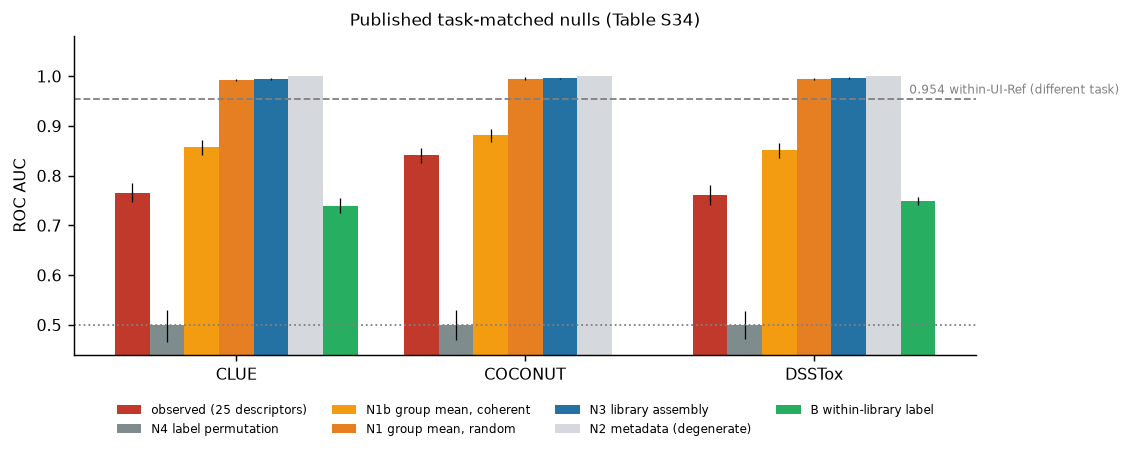

In [14]:
LABELS = {"observed_corrected_reference": "observed (25 descriptors)",
          "N4_within_pair_label_permutation": "N4 label permutation",
          "N1b_group_mean_coherent_cluster": "N1b group mean, coherent",
          "N1_group_mean_random_pseudodoc": "N1 group mean, random",
          "N3_library_assembly": "N3 library assembly",
          "N2_provenance_metadata_only": "N2 metadata (degenerate)",
          "B_within_library_provenance": "B within-library label"}
COLLS = ["CLUE", "COCONUT", "DSSTox"]
COLS = ["#c0392b", "#7f8c8d", "#f39c12", "#e67e22", "#2471a3", "#d5d8dc", "#27ae60"]
fig, ax = plt.subplots(figsize=(8.8, 3.6))
w, xs = 0.12, np.arange(len(COLLS))
for k, m in enumerate(SHOW):
    row = s34[s34.model == m].set_index("collection")
    v  = np.array([row.AUC.get(c, np.nan) for c in COLLS], dtype=float)
    lo = np.nan_to_num(v - np.array([row.AUC_lo.get(c, np.nan) for c in COLLS], dtype=float))
    hi = np.nan_to_num(np.array([row.AUC_hi.get(c, np.nan) for c in COLLS], dtype=float) - v)
    ax.bar(xs + (k - 3) * w, v, w, yerr=[lo, hi], color=COLS[k], label=LABELS[m],
           error_kw=dict(lw=0.7))
ax.axhline(0.5, color="grey", ls=":", lw=1)
ax.axhline(0.954, color="grey", ls="--", lw=1)
ax.text(2.33, 0.965, "0.954 within-UI-Ref (different task)", fontsize=6.5, color="grey")
ax.set_xticks(xs); ax.set_xticklabels(COLLS); ax.set_ylim(0.44, 1.08)
ax.set_ylabel("ROC AUC"); ax.set_title("Published task-matched nulls (Table S34)", fontsize=9.5)
ax.legend(fontsize=6.8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> The published panel of task-matched nulls, redrawn from the
released Table S34. For each external collection the observed corrected model (red) is the
<em>lowest</em> of the informative models: the library-assembly null N3 and the random-block
group-mean null N1 both exceed 0.99, the chemically coherent group-mean null N1b reaches
0.85–0.88, and only the label-permutation null N4 sits at chance. N2 (pale grey) is 1.000 by
construction and carries no weight. B is not computable for COCONUT, which releases no provenance
field. The dashed line is the 0.954 within-UI-Ref provenance value of Notebook 2, shown for
orientation only because it was estimated on a different task with different class priors. Error
bars are 95% bootstrap confidence intervals.</p>

The figure makes the paper's argument in one picture. If you were handed the red bars alone, you
would read 0.76–0.84 as moderate but real target-related separation. Placed next to the nulls
fitted inside the same design, the same bars read as *the weakest informative model in the
experiment*.

## 9. Comparing two models on the same molecules

We now have two AUCs, about 0.80 and 0.99, and we need their difference with an uncertainty
attached. The naive route — compare each model's own bootstrap interval and check for overlap — is
wrong, and understanding why is worth more than the rest of this section. The two models score
**the same molecules**: a test molecule that is unusually easy raises both AUCs together, a
mislabelled one lowers both together. The two estimates are positively correlated, and

$$\mathrm{Var}(\hat{A}_1 - \hat{A}_2) \;=\; \mathrm{Var}(\hat{A}_1) + \mathrm{Var}(\hat{A}_2) - 2\,\mathrm{Cov}(\hat{A}_1, \hat{A}_2).$$

Ignoring the covariance inflates the variance of the difference, wasting power and making
"overlapping intervals" a meaningless criterion: two correlated estimates can overlap while their
difference is overwhelmingly significant, which is what happens here. The paper uses both standard
ways of getting the covariance right.

### 9.1 The paired bootstrap

Resample *molecules*, not models. In each replicate draw a bootstrap sample of the test set, with
replacement and stratified by class so the class balance is preserved, recompute **both** AUCs on
that identical sample, and store the difference. The empirical distribution of those differences
is a distribution of the paired difference, with the covariance handled implicitly because the
two models always see the same resample.<sup class="c"><a href="#r3">[3]</a></sup>

**Traced by hand.** Take a test set of three positives $p_1,p_2,p_3$ and three negatives
$n_1,n_2,n_3$, and a replicate that draws positives $(p_1,p_1,p_3)$ and negatives $(n_2,n_2,n_3)$.
Both models are scored on exactly those six rows, giving nine positive–negative pairs. If model 1
ranks seven of the nine correctly, $\hat{A}_1 = 7/9$; model 2 is evaluated on the *same nine
pairs*, so if it gets eight right, $\hat{A}_2 = 8/9$ and this replicate contributes $-1/9$ to the
difference distribution. The percentile interval is the 2.5th and 97.5th percentiles of the stored
differences, and the bootstrap p-value is twice the smaller tail mass.

### 9.2 The DeLong test

The second route is analytic. DeLong, DeLong and Clarke-Pearson showed that the empirical AUC is
a two-sample U-statistic whose variance — and the covariance between two such statistics on the
same data — can be estimated from *placement values*: for each positive, the fraction of negatives
it outranks; for each negative, the fraction of positives it is outranked
by.<sup class="c"><a href="#r4">[4]</a></sup> The covariance matrix of the two AUCs is the sample
covariance of those placement values, with midranks handling ties, and the statistic is

$$Z \;=\; \frac{\hat{A}_1 - \hat{A}_2}{\sqrt{\widehat{\mathrm{Var}}(\hat{A}_1) + \widehat{\mathrm{Var}}(\hat{A}_2) - 2\,\widehat{\mathrm{Cov}}(\hat{A}_1,\hat{A}_2)}} \;\sim\; \mathcal{N}(0,1).$$

We will not re-derive the variance estimator; the point to take away is *what makes it a paired
test* — it estimates the covariance from the shared placement values rather than assuming
independence. The implementation below is the fast midrank form of Sun and Xu, which computes the
same quantity in $O(n \log n)$ instead of $O(n^2)$.<sup class="c"><a href="#r5">[5]</a></sup>

<div class="box warn">
<h4>Pitfall</h4>
<p>DeLong requires the two models to score the <em>same</em> molecules with the <em>same</em>
labels. It therefore applies to the observed model against N1, N1b, N3 and N2, where only the
features change, but <b>not</b> against N4, where the labels themselves are permuted. The paper
reports DeLong <em>Z</em> for the first group and a permutation p-value for N4, and this is why.
Reporting a DeLong statistic against a label-permutation null is a category error.</p>
</div>

In [15]:
from scipy.stats import rankdata, norm

def delong_two(y_true, s1, s2):
    """DeLong's test for two correlated ROC curves, fast midrank form (Sun & Xu 2014).

    Returns the two AUCs, their difference, the Z statistic and a two-sided p-value.
    Requires both score vectors to refer to the same molecules and the same labels.
    """
    pos = y_true == 1
    m, n = int(pos.sum()), int((~pos).sum())
    V10 = np.empty((2, m)); V01 = np.empty((2, n)); A = np.empty(2)
    for k, s in enumerate((s1, s2)):
        X, Y = s[pos], s[~pos]
        tx = rankdata(X, "average"); ty = rankdata(Y, "average")
        tz = rankdata(np.r_[X, Y], "average")
        V10[k] = (tz[:m] - tx) / n                 # placement of each positive among negatives
        V01[k] = 1.0 - (tz[m:] - ty) / m           # placement of each negative among positives
        A[k] = (tz[:m].sum() - m * (m + 1) / 2) / (m * n)
    S = np.cov(V10) / m + np.cov(V01) / n          # 2x2 covariance of the two AUCs
    diff = A[0] - A[1]
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]          # the paired variance
    Z = diff / np.sqrt(var)
    return A, diff, Z, 2 * norm.sf(abs(Z))

A, diff, Z, pval = delong_two(y, s_obs, s_n3)
print("observed AUC %.4f  |  N3 null AUC %.4f" % (A[0], A[1]))
print("paired difference %.4f   DeLong Z = %.2f   p = %.3g" % (diff, Z, pval))
print("published for UI-Ref vs CLUE: difference -0.229 [-0.247 to -0.210], Z = -24.25")

observed AUC 0.8003  |  N3 null AUC 0.9865
paired difference -0.1862   DeLong Z = -21.21   p = 7.15e-100
published for UI-Ref vs CLUE: difference -0.229 [-0.247 to -0.210], Z = -24.25


In [16]:
# Paired bootstrap: resample molecules, score BOTH models on the same resample.
# The paper used 2,000 replicates; 400 is enough for a two-decimal interval here.
N_BOOT = 400
ix_pos, ix_neg = np.where(y == 1)[0], np.where(y == 0)[0]
boot = np.empty(N_BOOT)
rb = np.random.default_rng(RANDOM_STATE)
for b in range(N_BOOT):
    ix = np.r_[rb.choice(ix_pos, len(ix_pos), True), rb.choice(ix_neg, len(ix_neg), True)]
    boot[b] = roc_auc_score(y[ix], s_obs[ix]) - roc_auc_score(y[ix], s_n3[ix])
ci = np.percentile(boot, [2.5, 97.5])
p_boot = 2 * min((boot >= 0).mean(), (boot <= 0).mean())
print("paired bootstrap difference (observed - N3): %.4f  95%% CI [%.4f, %.4f]" %
      (boot.mean(), *ci))
print("bootstrap p-value: %.4f  (smallest attainable with %d replicates = %.4f)" %
      (p_boot, N_BOOT, 2 / N_BOOT))
print("unpaired check -- interval half-widths added in quadrature would be wider,")
print("because the two models share every test molecule and are positively correlated.")

paired bootstrap difference (observed - N3): -0.1864  95% CI [-0.2051, -0.1722]
bootstrap p-value: 0.0000  (smallest attainable with 400 replicates = 0.0050)
unpaired check -- interval half-widths added in quadrature would be wider,
because the two models share every test molecule and are positively correlated.


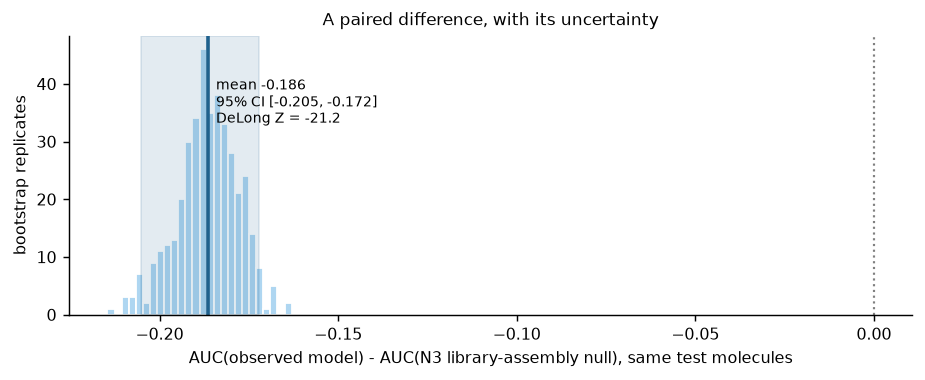

In [17]:
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.hist(boot, bins=26, color="#aed6f1", edgecolor="white")
ax.axvline(0, color="grey", ls=":", lw=1.2)
ax.axvline(boot.mean(), color="#1f618d", lw=2)
ax.axvspan(ci[0], ci[1], color="#1f618d", alpha=0.12)
ax.set_xlabel("AUC(observed model) - AUC(N3 library-assembly null), same test molecules")
ax.set_ylabel("bootstrap replicates")
ax.set_title("A paired difference, with its uncertainty", fontsize=9.5)
ax.text(boot.mean(), ax.get_ylim()[1] * 0.85,
        "  mean %.3f\n  95%% CI [%.3f, %.3f]\n  DeLong Z = %.1f" % (boot.mean(), *ci, Z),
        fontsize=7.5, va="top")
fig.tight_layout()

<p class="caption"><b>Figure 4.</b> Paired bootstrap distribution of the AUC difference between
the observed corrected model and the library-assembly null N3, over 400 replicates that resample
the same test molecules for both models. The whole distribution lies below zero — the null is
better on every replicate — and the shaded band is the 95% percentile interval. The DeLong
statistic printed in the panel is the analytic version of the same comparison and agrees with it.
The published analysis reports a difference of -0.229 (95% CI -0.247 to -0.210) with
<em>Z</em> = -24.25 for this collection, over 2,000 replicates.</p>

Both routes agree, as they usually do when the sample is large and the scores well behaved: the
difference is negative, far from zero, and its sign is not in doubt. The published analysis reports
paired differences of -0.229 (95% CI -0.247 to -0.210) against CLUE, -0.154 (-0.170 to -0.139)
against COCONUT and -0.234 (-0.254 to -0.215) against DSSTox, with bootstrap p < 0.001 and DeLong
Z of -24.25, -20.13 and -24.58.<sup class="c"><a href="#r1">[1]</a></sup>

<div class="exercise">
<h4>Exercise 2</h4>
<p>Replace <code>s_n3</code> in the DeLong cell by a randomly shuffled copy of <code>s_obs</code>
and confirm that <em>Z</em> is large and positive — the observed model beats a scrambled version
of itself. Then replace it by <code>s_obs</code> itself and confirm that the difference is exactly
zero and <em>Z</em> is undefined or zero, because the numerator and the covariance term vanish
together. These two checks are the minimum sanity test for any implementation of a paired
statistic you write yourself.</p>
</div>

## 10. Conditioning on the confounder

**Why this analysis exists.** The nulls establish that provenance information is a stronger
predictor than chemistry, but they are still a comparison of *aggregate* performance. A reader
could reasonably object: perhaps the observed model discriminates on chemistry precisely among
those molecules that provenance cannot separate, and the aggregate comparison hides it. The
conditioning analysis answers that objection directly. For the paper's claim to be wrong, a
substantial fraction of positive–negative pairs would have to remain comparable after conditioning
on provenance predictability, and the conditional AUC on those pairs would have to stay high.

The construction borrows the logic of stratification from epidemiology. Score every molecule with
the N3 library-assembly model, cut the scores into deciles, and ask how many positive–negative
*pairs* fall inside the same decile. A pair that straddles two deciles is a pair the confounder
already separates, and no comparison between its two members can be attributed to chemistry. The
fraction of same-decile pairs is the fraction of the comparison that is still interpretable, and
the AUC computed within those strata is the conditional estimate.

In [18]:
decile = pd.qcut(s_n3, 10, labels=False, duplicates="drop")   # strata of provenance score
comparable, num, den = 0, 0.0, 0.0
per_decile = []
for d in np.unique(decile):
    sel = decile == d
    npos, nneg = int((y[sel] == 1).sum()), int((y[sel] == 0).sum())
    pairs = npos * nneg
    comparable += pairs
    a = roc_auc_score(y[sel], s_obs[sel]) if npos and nneg else np.nan
    if pairs:
        num += (0 if np.isnan(a) else a) * pairs; den += pairs
    per_decile.append((int(d), npos, nneg, pairs, a))

total_pairs = int((y == 1).sum()) * int((y == 0).sum())
print(pd.DataFrame(per_decile, columns=["decile", "n_pos", "n_neg", "pairs", "AUC_within"])
      .round(3).to_string(index=False))
print("\ncomparable pairs: %d of %d = %.2f%%" % (comparable, total_pairs,
                                                 100 * comparable / total_pairs))
print("conditional AUC on comparable pairs: %.3f" % (num / den))
print("published for UI-Ref vs CLUE: 1.26% comparable, conditional AUC 0.632")

 decile  n_pos  n_neg  pairs  AUC_within
      0      8    761   6088       0.439
      1     15    195   2925       0.528
      2     40    199   7960       0.745
      3    183     63  11529       0.676
      4    972      0      0         NaN

comparable pairs: 28502 of 1483524 = 1.92%
conditional AUC on comparable pairs: 0.629
published for UI-Ref vs CLUE: 1.26% comparable, conditional AUC 0.632


The per-decile table shows the mechanism plainly: almost every decile is pure, containing either
UI-Ref molecules or decoys but not both in any quantity. Only where the two classes co-occur can
a pair be compared at all, and that happens in a small minority of pairs. The published values are
1.26%, 1.21% and 0.95% of positive–negative pairs remaining comparable for CLUE, COCONUT and
DSSTox, with conditional AUCs of 0.632, 0.742 and 0.666 on those pairs — so 98.7–99.1% of the
corrected discrimination occurs between molecules that provenance-derived information already
separates.<sup class="c"><a href="#r1">[1]</a></sup> Our reconstruction gives a slightly larger
comparable fraction and essentially the same conditional AUC; the difference follows from the
reduced N3 feature set and the modified fold rule, both of which make our N3 model marginally
weaker and therefore its deciles marginally less pure.

<div class="box key">
<h4>Key idea</h4>
<p>Conditioning converts "there may be confounding" into "here is how much of my comparison
survives it". The number to report is the fraction of comparable units, not only the conditional
effect size: a conditional AUC of 0.63 computed on 1% of the pairs is a statement about 1% of the
data, and saying so is not a weakness of the analysis but its main result.</p>
</div>

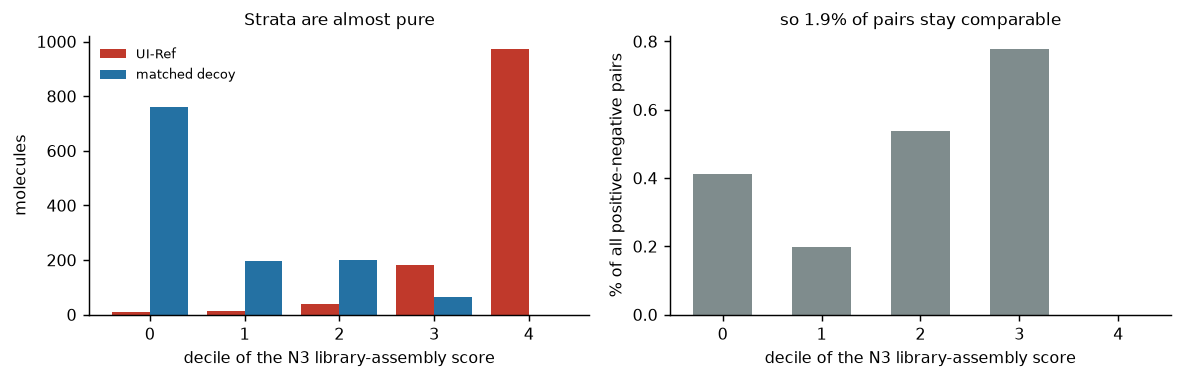

In [19]:
per = pd.DataFrame(per_decile, columns=["decile", "n_pos", "n_neg", "pairs", "AUC_within"])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.0))
ax1.bar(per.decile - 0.2, per.n_pos, 0.4, color="#c0392b", label="UI-Ref")
ax1.bar(per.decile + 0.2, per.n_neg, 0.4, color="#2471a3", label="matched decoy")
ax1.set_xlabel("decile of the N3 library-assembly score"); ax1.set_ylabel("molecules")
ax1.set_title("Strata are almost pure", fontsize=9.5); ax1.legend(fontsize=7, frameon=False)
ax2.bar(per.decile, 100 * per.pairs / total_pairs, 0.6, color="#7f8c8d")
ax2.set_xlabel("decile of the N3 library-assembly score")
ax2.set_ylabel("% of all positive-negative pairs")
ax2.set_title("so %.1f%% of pairs stay comparable" % (100 * comparable / total_pairs), fontsize=9.5)
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> Left: composition of each decile of the library-assembly
score. UI-Ref molecules and matched decoys occupy almost disjoint ranges of the score, so most
deciles contain only one class. Right: the share of all positive–negative pairs that fall inside
a single decile, which is the share of the comparison that conditioning leaves interpretable;
summed over deciles it is the comparable-pair fraction printed above. The published analysis
reports 1.26% for this collection.</p>

## 11. Many tests at once: false-discovery control and random-effects pooling

The last two tools in the paper's inferential kit are not about comparing two models; they are
about what happens when you test many hypotheses on clustered data. They produced the paper's
motif conclusions, and they are the reason those conclusions are negative.

### 11.1 The problem, in two parts

The study asks whether any of 14 structural motifs — hydroxamate, thiourea, urea, catechol,
carboxylate, thiol, hydrazone, phosphinic/phosphonic, selenium, any chelator, and the PAINS,
Brenk, NIH and combined alert sets — is associated with potency, defined as pAct $\ge$ 6. Two
things go wrong if you test them naively.

**Part one: multiplicity.** Fourteen independent tests at $\alpha = 0.05$ give a probability
$1 - 0.95^{14} \approx 0.51$ of at least one false positive. Benjamini–Hochberg controls the
*false discovery rate* — the expected proportion of false positives among rejected hypotheses —
rather than the probability of any false positive. Sort the p-values
$p_{(1)} \le \dots \le p_{(m)}$, find the largest $k$ with

$$p_{(k)} \;\le\; \frac{k}{m}\,q,$$

and reject hypotheses $1,\dots,k$.<sup class="c"><a href="#r6">[6]</a></sup> It is less
conservative than Bonferroni because it adapts to how many of the hypotheses look true, which is
what makes it the standard choice in high-dimensional biology.

**Part two: clustering.** The molecules are not independent. They arrive in publications, and
molecules from one publication are a congeneric series assayed in one laboratory under one
protocol. Pooling them as if they were independent counts each publication many times over and
produces confidence intervals that are far too narrow.

In [20]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

MOTIFS = ["hydroxamate", "thiourea", "urea", "catechol", "carboxylate", "thiol", "hydrazone",
          "phosphinic_phosphonic", "selenium", "any_chelator", "PAINS", "BRENK", "NIH",
          "any_alert"]
pot = uiref[uiref.pAct_median.notna()].copy()
pot["potent"] = (pot.pAct_median >= 6).astype(int)

rows = []
for mo in MOTIFS:
    tab = pd.crosstab(pot[mo].astype(int), pot.potent)
    if tab.shape == (2, 2):
        orr, p = fisher_exact(tab.to_numpy())
        rows.append((mo, int(pot[mo].sum()), orr, p))
pooled = pd.DataFrame(rows, columns=["motif", "n_with_motif", "OR_pooled", "p_pooled"])
pooled["p_BH"] = multipletests(pooled.p_pooled, method="fdr_bh")[1]
print("molecules with a quantitative pAct: %d, of which potent (pAct >= 6): %d" %
      (len(pot), int(pot.potent.sum())))
print(pooled.round(4).to_string(index=False))
print("\nsurviving Benjamini-Hochberg at q = 0.05: %d of %d" %
      (int((pooled.p_BH < 0.05).sum()), len(pooled)))

molecules with a quantitative pAct: 1110, of which potent (pAct >= 6): 178
                motif  n_with_motif  OR_pooled  p_pooled   p_BH
          hydroxamate            21     0.0000    0.0362 0.0461
             thiourea           281     2.4200    0.0000 0.0000
                 urea            16     0.0000    0.0906 0.1057
             catechol           146     0.4733    0.0107 0.0167
          carboxylate            64     0.2448    0.0078 0.0136
                thiol             2     0.0000    1.0000 1.0000
            hydrazone            98     7.1940    0.0000 0.0000
phosphinic_phosphonic            96     0.2671    0.0012 0.0034
             selenium            53     9.5082    0.0000 0.0000
         any_chelator           636     1.7189    0.0017 0.0039
                PAINS           207     0.6032    0.0353 0.0461
                BRENK           950     1.3965    0.2020 0.2175
                  NIH           234     1.8810    0.0009 0.0030
            any_alert        

Eleven of the fourteen motifs survive false-discovery control on the pooled tests, which is
exactly what the paper reports.<sup class="c"><a href="#r1">[1]</a></sup> Taken at face value this
is a rich set of structure–activity findings, and selenium looks spectacular, with a pooled odds
ratio above 9.

### 11.2 Random-effects pooling by publication

Now repeat the analysis with the clustering respected. For each source document $j$ in which both
classes of the motif and both potency outcomes occur, compute a within-document log odds ratio
$y_j$ and its variance $v_j$ from the $2\times2$ table, using the Haldane–Anscombe correction of
adding 0.5 to each cell so that zero cells do not produce infinities. A document in which the
motif is absent, or in which no molecule is potent, carries no information about the association
and is dropped: it is not an *informative stratum*.

The DerSimonian–Laird random-effects estimator then pools the informative strata while allowing
the true effect to differ between them.<sup class="c"><a href="#r7">[7]</a></sup> With
fixed-effect weights $w_j = 1/v_j$ and Cochran's $Q = \sum_j w_j (y_j - \bar{y}_F)^2$, the
between-study variance is

$$\hat{\tau}^2 \;=\; \max\!\left(0,\; \frac{Q - (k-1)}{\sum_j w_j - \sum_j w_j^2 / \sum_j w_j}\right),$$

the random-effects weights are $w_j^{*} = 1/(v_j + \hat{\tau}^2)$, and the pooled estimate is
$\hat{\mu} = \sum_j w_j^{*} y_j / \sum_j w_j^{*}$ with standard error
$(\sum_j w_j^{*})^{-1/2}$. The heterogeneity is summarised by
$I^2 = \max(0, (Q - k + 1)/Q)$, the share of the observed variation that is not attributable to
sampling error.<sup class="c"><a href="#r8">[8]</a></sup>

In [21]:
def dersimonian_laird(df, motif, min_strata=3):
    """Random-effects pooling of per-document log odds ratios (DerSimonian & Laird 1986)."""
    ys, vs = [], []
    for _, g in df.groupby("grp_document"):
        a = ((g[motif] == 1) & (g.potent == 1)).sum(); b = ((g[motif] == 1) & (g.potent == 0)).sum()
        c = ((g[motif] == 0) & (g.potent == 1)).sum(); d = ((g[motif] == 0) & (g.potent == 0)).sum()
        if min(a + b, c + d) == 0 or (a + c) == 0 or (b + d) == 0:
            continue                                   # not an informative stratum
        a, b, c, d = a + 0.5, b + 0.5, c + 0.5, d + 0.5   # Haldane-Anscombe correction
        ys.append(np.log(a * d / (b * c))); vs.append(1 / a + 1 / b + 1 / c + 1 / d)
    k = len(ys)
    if k < min_strata:
        return None
    ys, vs = np.array(ys), np.array(vs); w = 1 / vs
    mu_fixed = (w * ys).sum() / w.sum()
    Q = (w * (ys - mu_fixed) ** 2).sum()
    C = w.sum() - (w ** 2).sum() / w.sum()
    tau2 = max(0.0, (Q - (k - 1)) / C)
    wr = 1 / (vs + tau2); mu = (wr * ys).sum() / wr.sum(); se = np.sqrt(1 / wr.sum())
    return dict(k_strata=k, OR=np.exp(mu), lo=np.exp(mu - 1.96 * se), hi=np.exp(mu + 1.96 * se),
                p=2 * norm.sf(abs(mu / se)), I2=100 * (max(0.0, (Q - k + 1) / Q) if Q > 0 else 0.0))

potd = pot[pot.grp_document.notna()].copy()
re_rows = [dict(motif=mo, **r) for mo in MOTIFS
           if (r := dersimonian_laird(potd, mo)) is not None]
re = pd.DataFrame(re_rows)
re["p_BH"] = multipletests(re.p, method="fdr_bh")[1]
print(re.round(4).to_string(index=False))
print("\nestimable motifs (>= 3 informative document strata): %d of %d" % (len(re), len(MOTIFS)))
print("surviving Benjamini-Hochberg at q = 0.05: %d" % int((re.p_BH < 0.05).sum()))
print("smallest adjusted p-value: %.3f" % re.p_BH.min())

       motif  k_strata     OR     lo      hi      p      I2   p_BH
    thiourea         3 3.2816 0.5992 17.9730 0.1708  7.1483 0.6442
    catechol         7 1.9282 0.4999  7.4375 0.3404 15.6349 0.7383
 carboxylate         6 0.6556 0.1785  2.4086 0.5248 15.1797 0.7873
   hydrazone         4 1.1062 0.2972  4.1177 0.8804  0.0000 0.9599
any_chelator        11 0.6273 0.2068  1.9030 0.4102 45.1533 0.7383
       PAINS         9 1.8533 0.6993  4.9119 0.2147  0.0000 0.6442
       BRENK         6 0.9670 0.2614  3.5778 0.9599 38.4184 0.9599
         NIH        14 2.1673 1.0403  4.5152 0.0389  0.4334 0.3498
   any_alert         6 1.0736 0.2436  4.7312 0.9252 44.3183 0.9599

estimable motifs (>= 3 informative document strata): 9 of 14
surviving Benjamini-Hochberg at q = 0.05: 0
smallest adjusted p-value: 0.350


The reversal is complete: eleven associations survive multiplicity control when molecules are
pooled, none once publications are treated as the clusters they are. The published analysis reaches
the same conclusion with five estimators rather than two: "Eleven of the 14 motifs survive
false-discovery-rate control at 0.05 on the pooled Fisher tests, whereas none of the 12 estimable
random-effects tests survives at either 0.05 or 0.10, the smallest adjusted p-value being
0.245."<sup class="c"><a href="#r1">[1]</a></sup> Our stricter requirement of three informative
strata leaves fewer estimable motifs than the paper's 12; the conclusion is identical.

The printed $I^2$ values tell you where the heterogeneity is: the broad indicators — any chelating
motif, any structural alert, the Brenk set — show substantial between-document heterogeneity,
around 40–45%, matching the published 45.6%, 44.3% and 40.0%.<sup class="c"><a href="#r1">[1]</a></sup>
A single pooled odds ratio for those motifs is not summarising one effect; it is averaging over
publications that disagree.

Selenium is the case the paper uses to make the lesson concrete, and it is worth stating in full
because it is the kind of result that gets published. Selenium occurs in 53 of the 1,110 labelled
molecules and has a single informative document stratum. Its pooled odds ratio is 9.51 (95% CI
5.34–16.94; Fisher p = 4.8e-14, BH-adjusted p = 3.3e-13) — and the two within-document estimates
of that one stratum are 0.095 (0.004–2.175) by Mantel–Haenszel stratification and 0.114
(0.006–2.161) by the exact conditional method, both including 1. The two numbers are two estimators
of the same single stratum, not two strata. "The apparent reversal between the pooled and the stratified
estimate is a property of a single stratum, not a finding about selenium."<sup class="c"><a href="#r1">[1]</a></sup>
Our pooled table prints the same 9.51, and our random-effects table does not contain selenium at
all, because it has fewer than three informative strata — which is the correct behaviour.

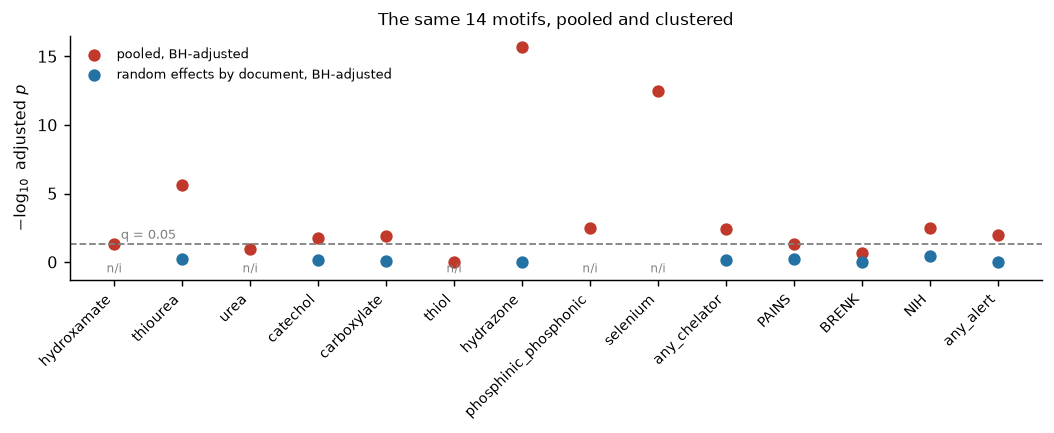

In [22]:
mer = pooled.merge(re[["motif", "p_BH", "k_strata", "I2"]], on="motif",
                   how="left", suffixes=("_pooled", "_random"))
fig, ax = plt.subplots(figsize=(8.2, 3.4))
xpos = np.arange(len(mer))
ax.scatter(xpos, -np.log10(mer.p_BH_pooled), s=34, color="#c0392b", label="pooled, BH-adjusted")
ok = mer.p_BH_random.notna()
ax.scatter(xpos[ok], -np.log10(mer.p_BH_random[ok]), s=34, color="#2471a3",
           label="random effects by document, BH-adjusted")
for i in xpos[~ok]:
    ax.text(i, -0.75, "n/i", ha="center", fontsize=6.5, color="grey")
ax.set_ylim(-1.3, None)
ax.axhline(-np.log10(0.05), color="grey", ls="--", lw=1)
ax.text(0.1, -np.log10(0.05) + 0.4, "q = 0.05", fontsize=7, color="grey", ha="left")
ax.set_xticks(xpos); ax.set_xticklabels(mer.motif, rotation=45, ha="right", fontsize=7.5)
ax.set_ylabel(r"$-\log_{10}$ adjusted $p$")
ax.set_title("The same 14 motifs, pooled and clustered", fontsize=9.5)
ax.legend(fontsize=7, frameon=False, loc="upper left")
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> Benjamini–Hochberg adjusted p-values for the association
between each of 14 structural motifs and potency, on the 1,110 molecules carrying a quantitative
pAct. Red: pooled Fisher tests treating molecules as independent; blue: DerSimonian–Laird
random-effects pooling of per-document log odds ratios. Points above the dashed line are
significant at a false-discovery rate of 0.05. Eleven red points clear the line and no blue point
does; motifs marked "n/i" have fewer than three informative document strata and are not estimable
by the clustered analysis at all. The difference between the two series is not a difference of
statistical taste — it is the difference between counting 1,110 molecules and counting the
publications that produced them.</p>

<div class="box bridge">
<h4>Bridge</h4>
<p>This is the same unit-of-analysis question you met in the bioinformatics course when deciding
whether replicate sequencing runs count as biological replicates. The rule generalises: identify
the unit that was independently sampled, and let every uncertainty estimate be computed at that
unit. Here the unit is the publication, not the molecule.</p>
</div>

## 12. Not attributable is not absent

Everything in this notebook leads to one sentence, and the sentence is the hardest thing in the
paper to state correctly. Let us assemble it from the evidence.

- The corrected comparison exceeds the within-pair permutation null by 0.263–0.341, at the
  permutation p-value floor. **A difference exists and is reproducible.**<sup class="c"><a href="#r1">[1]</a></sup>
- It falls *below* the library-assembly null by 0.154–0.234, with DeLong Z from -20.13 to -24.58.
  **A channel that cannot contain target chemistry explains more of the separation than the
  chemistry does.**<sup class="c"><a href="#r1">[1]</a></sup>
- A purely administrative label inside an external library is predicted at 0.7397–0.7494 from the
  same descriptors. **Reaching the 0.762–0.841 band is not diagnostic of target-related
  chemistry.**<sup class="c"><a href="#r1">[1]</a></sup>
- After conditioning, 0.95–1.26% of positive–negative pairs remain comparable. **98.7–99.1% of the
  discrimination happens between molecules that provenance already
  separates.**<sup class="c"><a href="#r1">[1]</a></sup>

The conclusion is a conjunction and both halves must be stated together: the residual separation
is *detectable*, and it is *not attributable* to target chemistry rather than residual provenance
structure. What does not follow is that the chemistry is absent — "These results do not establish
that target-related chemical differences are absent. What they establish is narrower: the
conventional design cannot apportion the observed separation between target-related chemistry and
provenance."<sup class="c"><a href="#r1">[1]</a></sup>

<div class="box key">
<h4>Key idea</h4>
<p><b>Not attributable</b> is a statement about a <em>design</em>: this experiment cannot tell the
two explanations apart. <b>Absent</b> is a statement about the <em>world</em>: the effect is not
there. A design that cannot distinguish A from B is also a design that cannot establish that A is
zero. Claiming absence from a failure to attribute is the mirror image of claiming a mechanism
from an AUC above 0.5 — the same error, made in the opposite direction.</p>
</div>

Two practical consequences follow. First, write the negative result as a scope statement rather
than a refutation: "our design cannot distinguish X from Y; distinguishing them would require Z"
is informative and falsifiable, whereas "there is no X" is neither if Z was never run. Second, say
what Z would be. Here the missing experiment compares molecules assayed against urease with
molecules assayed against a different target *within the same publications*, holding provenance
fixed by construction; the paper's multilevel analysis shows it cannot be run in this corpus,
because source publication accounts for 98.4% of the variation in assay organism, 81.8% of
scaffold-class variation and 85.9% of endpoint variation.<sup class="c"><a href="#r1">[1]</a></sup>

<div class="box warn">
<h4>Pitfall</h4>
<p>The random forest is not on trial here, and swapping it for a gradient-boosted ensemble or a
neural network would change nothing in this notebook: every null uses the <em>same</em> estimator
as the observed model, so estimator choice cancels out of the
difference.<sup class="c"><a href="#r2">[2]</a></sup> When a result is driven by what the features
encode rather than by how they are combined, a better model makes the problem worse, not better,
because it extracts the confounding channel more efficiently.</p>
</div>

## 13. Summary

You should now be able to explain the following without notes.

- An AUC is interpretable only against a comparator, and 0.5 is almost never the right one: the
  right comparator is a model fitted inside the same design, with the same estimator, folds and
  seed, that cannot use the explanation you want to defend.
- A **label-permutation null** answers "is there any signal": its mean is 0.5 by construction, its
  spread measures how much apparent signal the design can manufacture, and with $B$ replicates the
  smallest attainable p-value is $1/(B+1)$.
- A **task-matched null** answers "is the signal the one I claim". N3 gives a model five numbers
  about a molecule's position inside its own library and reaches 0.995–0.996 where the observed
  model reaches 0.762–0.841 — the null is *better*.
- Reading an **inversion**: the observed model is not below chance; the comparator was never 0.5.
  What collapses is attribution, not existence.
- A null must be matched to its observed model: change the folds and refit both sides.
- Two models scored on the **same molecules** are positively correlated, so their difference is a
  paired quantity — estimate it with a **paired bootstrap** or the **DeLong test**, never by
  checking whether single-model intervals overlap. DeLong needs identical labels, so it applies
  against N1, N1b, N3 and N2 but never against a label-permutation null.
- A null can be **degenerate by construction** (N2: metadata availability *is* the label); a
  guaranteed AUC of 1.000 carries no inferential weight.
- **Conditioning** reports two numbers: the fraction of comparable units — about 1% of pairs here —
  and the conditional effect among them.
- **Benjamini–Hochberg** controls the expected proportion of false positives among rejections;
  **random-effects pooling** respects clustering and $I^2$ measures the excess between-cluster
  variation. Eleven motif associations survive BH when molecules are pooled, none once
  publications are the unit.
- **Not attributable** is a property of a design, **absent** of the world. Never convert one into
  the other.

## 14. Self-assessment

<details><summary>Q1. Why is an AUC of 0.76 not evidence for target-related chemistry, even when
the permutation p-value is at its floor?</summary>
The permutation null only rules out the hypothesis that the features carry no information about
the labels. Both candidate explanations — target chemistry and deposition provenance — predict an
AUC above 0.5, so clearing it discriminates between nothing. You need a null consistent with one
explanation and incapable of the other.
</details>

<details><summary>Q2. In the within-pair permutation, why permute inside pairs instead of
shuffling all 2,436 labels?</summary>
Free shuffling breaks the matched-pair structure and changes the design, so the null would no
longer be matched to the observed model. Permuting inside pairs preserves the class balance, the
pair structure and every descriptor's marginal distribution, destroying only the link between a
molecule and its collection label.
</details>

<details><summary>Q3. With 40 permutation replicates, what is the smallest p-value you can report,
and why is that not a defect?</summary>
$1/(1+40) \approx 0.024$. The quantity of interest is the null's location and spread, which 40
replicates estimate adequately. A p-value below 0.001 would need at least 1,000 replicates and
would add nothing to an effect size of 0.3 AUC units with a tight interval.
</details>

<details><summary>Q4. What does the N3 null know about a molecule, and what does it not
know?</summary>
It knows how frequent the molecule's Bemis–Murcko scaffold is in a size-standardised sample of its
own library and how dense its ECFP4 neighbourhood is there. It knows no molecular weight, logP,
polar surface area, ring count or element composition: it describes a position inside a library,
not a molecule.
</details>

<details><summary>Q5. Why must the folds be regrouped by block for the group-mean nulls N1 and
N1b?</summary>
A block mean carries information about every molecule in the block, including test molecules, so
with document-grouped folds the test descriptors would have contributed to the training features.
Regrouping by block makes each block entirely training or entirely test, and the observed model
must be refitted under the same regrouping so the comparison stays matched.
</details>

<details><summary>Q6. Give two reasons why judging two models by whether their individual
confidence intervals overlap is wrong.</summary>
The two AUCs are computed on the same molecules and are positively correlated, so ignoring the
covariance inflates the variance of the difference; and interval overlap tests no hypothesis about
the difference, since correlated estimates can overlap while the paired difference excludes zero
by a wide margin.
</details>

<details><summary>Q7. Why can the DeLong test be applied to the observed model against N3 but not
against N4?</summary>
DeLong estimates the covariance of two AUCs computed from the same labels and the same molecules,
differing only in the scores. N3 changes the feature representation and keeps the labels, so the
comparison is well defined. N4 permutes the labels themselves, so the two AUCs are not estimating
the same quantity on the same data, and the covariance DeLong needs does not exist. For N4 the
correct summary is the permutation distribution.
</details>

<details><summary>Q8. Reading the conditioning cell: the comparable-pair fraction is about 1%.
Does that mean 99% of the molecules were discarded?</summary>
No. No molecule is discarded. The statistic counts positive–negative <em>pairs</em>, and a pair is
comparable only when both members fall in the same decile of the provenance score. Because the
score separates the two classes almost completely, most pairs straddle deciles. The 1% is the
share of the <em>comparisons</em> implicit in the AUC that conditioning leaves interpretable.
</details>

<details><summary>Q9. Eleven motif associations survive Benjamini–Hochberg and none survives
random-effects pooling. Which analysis is wrong?</summary>
Neither, arithmetically; they answer different questions. The pooled analysis treats molecules as
independent, which they are not, so its p-values are too small. The clustered answer is the one to
report, and the gap between the two measures how much the pooled analysis over-counted.
</details>

<details><summary>Q10. A motif has one informative document stratum and a pooled odds ratio of
9.51 with an adjusted p-value of 3.3e-13. What should you write?</summary>
That the association is not identified by these data. One informative stratum means the entire
within-publication evidence comes from a single publication, so the pooled estimate is a
between-publication contrast wearing the clothes of a structure–activity relationship. Report the
occurrence counts and the number of informative strata, and decline to give a direction.
</details>

<details><summary>Q11. State the difference between "not attributable" and "absent" in one
sentence each, using this study as the example.</summary>
Not attributable: the corrected design cannot apportion the 0.762–0.841 separation between urease
chemistry and residual provenance structure, because a provenance-only null reaches 0.995–0.996 in
the same task. Absent: urease inhibitors do not differ chemically from external libraries — a claim
this study does not make and could not support, since the required publication-internal
comparison cannot be run in this corpus.
</details>

<details><summary>Q12. You replace the random forest with a gradient-boosted ensemble and every
AUC rises by 0.02. What changes in the conclusions?</summary>
Nothing, provided every null is refitted with the same estimator: the conclusions rest on
differences between models sharing estimator, folds and seed, so a uniformly better learner raises
both sides. If it widens the gap in favour of the nulls, the confounding conclusion is reinforced,
because the extra capacity is spent on the provenance channel.
</details>

## Glossary

<dl class="gloss">
<dt>Null model</dt><dd>A model fitted inside the same experiment as the observed model, built to be
consistent with the explanation one wishes to rule out. Its score is a comparator, not a result.</dd>
<dt>Label-permutation null (y-scrambling)</dt><dd>A null obtained by randomly reassigning the
labels while keeping the features. Expected score is chance; the spread quantifies how much
apparent performance the design can produce by luck.</dd>
<dt>Task-matched null</dt><dd>A null that keeps the design, estimator, folds and seed of the
observed model and changes only the feature representation, so that the difference between the two
isolates one mechanism.</dd>
<dt>Library-assembly feature</dt><dd>A feature describing a molecule's position within its own
source library — own-library scaffold frequency, fingerprint-neighbourhood density — rather than
any absolute chemical property.</dd>
<dt>Degenerate null</dt><dd>A null whose score is determined before fitting, typically because a
feature is structurally present in one class and absent in the other. Carries no inferential
weight.</dd>
<dt>Paired bootstrap</dt><dd>Resampling of test units in which both models are rescored on the
same resample, so that the correlation between their performance estimates is handled
implicitly.</dd>
<dt>DeLong test</dt><dd>An analytic test for the difference between two correlated ROC AUCs,
estimating their covariance from placement values computed on the shared sample.</dd>
<dt>Placement value</dt><dd>For a positive, the fraction of negatives it outranks; for a negative,
the fraction of positives it is outranked by. The building block of DeLong's variance
estimate.</dd>
<dt>Comparable pair</dt><dd>A positive–negative pair whose members fall in the same stratum of the
confounder, so that their comparison is not already explained by it.</dd>
<dt>False discovery rate</dt><dd>The expected proportion of false positives among rejected
hypotheses. Controlled by the Benjamini–Hochberg procedure.</dd>
<dt>Informative stratum</dt><dd>A cluster (here, a source publication) that contains variation in
both the exposure and the outcome, and therefore contributes to a within-cluster estimate.</dd>
<dt>Random-effects pooling</dt><dd>Combining per-cluster estimates while allowing the true effect
to vary between clusters, with the between-cluster variance estimated from the data.</dd>
<dt>I-squared</dt><dd>The share of observed variation across clusters that exceeds what sampling
error alone would produce.</dd>
<dt>Not attributable</dt><dd>A property of a design: the experiment cannot apportion an observed
effect between two candidate explanations. Distinct from <em>absent</em>, which is a property of
the world.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Farías-Abarca J, Urra G, Henríquez C, Yáñez O, Osorio MI, Palma J, Morales-Quintana L,
Suardíaz R, Bustos D. Provenance-Associated Confounding in Cross-Collection Comparisons of Urease
Inhibitors: A Quantified Reference Scale and a Domain-Aware Alternative. <em>Int J Mol Sci</em>.
2026;27(20):9159. <a href="https://doi.org/10.3390/ijms27209159">doi:10.3390/ijms27209159</a></li>
<li id="r2">Breiman L. Random forests. <em>Mach Learn</em>. 2001;45(1):5-32.
<a href="https://doi.org/10.1023/A:1010933404324">doi:10.1023/A:1010933404324</a></li>
<li id="r3">Efron B. Bootstrap methods: another look at the jackknife. <em>Ann Stat</em>.
1979;7(1):1-26. <a href="https://doi.org/10.1214/aos/1176344552">doi:10.1214/aos/1176344552</a></li>
<li id="r4">DeLong ER, DeLong DM, Clarke-Pearson DL. Comparing the areas under two or more
correlated receiver operating characteristic curves: a nonparametric approach.
<em>Biometrics</em>. 1988;44(3):837-845.
<a href="https://doi.org/10.2307/2531595">doi:10.2307/2531595</a></li>
<li id="r5">Sun X, Xu W. Fast implementation of DeLong's algorithm for comparing the areas under
correlated receiver operating characteristic curves. <em>IEEE Signal Process Lett</em>.
2014;21(11):1389-1393.
<a href="https://doi.org/10.1109/LSP.2014.2337313">doi:10.1109/LSP.2014.2337313</a></li>
<li id="r6">Benjamini Y, Hochberg Y. Controlling the false discovery rate: a practical and powerful
approach to multiple testing. <em>J R Stat Soc Series B</em>. 1995;57(1):289-300.
<a href="https://doi.org/10.1111/j.2517-6161.1995.tb02031.x">doi:10.1111/j.2517-6161.1995.tb02031.x</a></li>
<li id="r7">DerSimonian R, Laird N. Meta-analysis in clinical trials. <em>Control Clin Trials</em>.
1986;7(3):177-188.
<a href="https://doi.org/10.1016/0197-2456(86)90046-2">doi:10.1016/0197-2456(86)90046-2</a></li>
<li id="r8">Higgins JPT, Thompson SG. Quantifying heterogeneity in a meta-analysis.
<em>Stat Med</em>. 2002;21(11):1539-1558.
<a href="https://doi.org/10.1002/sim.1186">doi:10.1002/sim.1186</a></li>
<li id="r9">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J Chem Inf Model</em>.
2010;50(5):742-754. <a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r10">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks.
<em>J Med Chem</em>. 1996;39(15):2887-2893.
<a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r11">Mysinger MM, Carchia M, Irwin JJ, Shoichet BK. Directory of Useful Decoys, Enhanced
(DUD-E): better ligands and decoys for better benchmarking. <em>J Med Chem</em>.
2012;55(14):6582-6594. <a href="https://doi.org/10.1021/jm300687e">doi:10.1021/jm300687e</a></li>
<li id="r12">Wallach I, Heifets A. Most ligand-based classification benchmarks reward memorization
rather than generalization. <em>J Chem Inf Model</em>. 2018;58(5):916-932.
<a href="https://doi.org/10.1021/acs.jcim.7b00403">doi:10.1021/acs.jcim.7b00403</a></li>
<li id="r13">Rücker C, Rücker G, Meringer M. y-Randomization and its variants in QSPR/QSAR.
<em>J Chem Inf Model</em>. 2007;47(6):2345-2357.
<a href="https://doi.org/10.1021/ci700157b">doi:10.1021/ci700157b</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed.
Springer; 2009. Chapters 7 (model assessment) and 8 (bootstrap). Free PDF from the authors.</li>
<li>James G, Witten D, Hastie T, Tibshirani R. <em>An Introduction to Statistical Learning with
Applications in Python</em>. Springer; 2023. Chapter 5 for resampling. Free PDF.</li>
<li>Efron B, Tibshirani RJ. <em>An Introduction to the Bootstrap</em>. Chapman &amp; Hall; 1993.
The standard reference for percentile and paired bootstrap intervals.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>Ojala M, Garriga GC. Permutation tests for studying classifier performance.
<em>J Mach Learn Res</em>. 2010;11:1833-1863.
<a href="https://jmlr.org/papers/v11/ojala10a.html">jmlr.org/papers/v11/ojala10a.html</a> — the
two permutation schemes (labels versus features) and what each tests.</li>
<li>scikit-learn user guide, <em>Cross-validation iterators for grouped data</em>:
<a href="https://scikit-learn.org/stable/modules/cross_validation.html">scikit-learn.org/stable/modules/cross_validation.html</a></li>
<li>Reproduction scripts and the released supplementary tables for this study:
<a href="https://github.com/DanielBustosG/Urease-provenance-audit">github.com/DanielBustosG/Urease-provenance-audit</a></li>
</ul>